In [1]:
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np
import pandas as pd
from os import listdir
from os.path import join, isfile
from matplotlib import gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
from Scheme import *
import seaborn as sns
%matplotlib inline
sns.set_context('talk')

signaling 216 808 ['8.36E-12    -1.00']
signaling 215 809 ['4.00E-10', '0.00']
signaling 249 840 ['3.50E-12    -2.66']
signaling 248 841 ['5.98E-15', '0.18']
signaling 293 846 ['5.18E-32    -0.80']
signaling 286 886 ['2.88E-10', '0']
signaling 288 891 ['4.98E-10', '0.']
signaling 274 941 ['5.49E+13    -6.']
signaling 270 943 ['3.00E+08', '0']
signaling 253 951 ['1.90E-32', '0.00']


In [2]:
aux_sch = Scheme([], [], [], search_first=False)

In [5]:
dirs_to_test = ['1D_PAC/opt2104_extended', '1D_PAC/hd2094_venot_extended']
loss_dirs = ['1D_PAC/hd2094_extended']

In [6]:
dfs_to_test = []
for dir_ in dirs_to_test: 
    loss, df = aux_sch.get_loss([], ideal_dirs=loss_dirs, insert_dirs=[dir_], imp_molecs=imp_molecs, force_run=True,
                 path='')
    dfs_to_test.append(df[0])
    print(dir_,'Combined:', loss, 'Major:', aux_sch._major_loss, 'MRD:', aux_sch.losses, 'All', aux_sch._rel_all)

1D_PAC/opt2104_extended Combined: 0.5694707997703023 Major: [281.76340972806923] MRD: [0.5694707997703023] All [1450.165784274658]
1D_PAC/hd2094_venot_extended Combined: 0.6824824392018303 Major: [40.927251153773035] MRD: [0.6824824392018303] All [40.927251153773035]


In [7]:
def spagetti(test_df, to_beat_df, to_match_df, imp_molecs=imp_molecs, figsize=(12,10),
            y_var='pressure[bar]', legend_coords=(0.25, 1.5), fname='spagetti',
            extra_df=None, extra_model='', coral_model='This work', fontsize=17, extra_width=3, tick_size=17, 
             colors=['violet', 'dodgerblue','darkgreen', 'coral'], gridspec_kw={'wspace': .2,
                                                                                'hspace': .5,
                                                                                'width_ratios':[1,.25, 1, .25] },
            grid_cols = 2):
    plt.close('all')
    lmols = len(imp_molecs)
    nrows = int(lmols/grid_cols)
    fig, axes = plt.subplots(nrows=nrows, ncols=int(2*grid_cols), figsize=figsize,  
                             gridspec_kw=gridspec_kw)

    for m_i, m in zip(range(lmols), imp_molecs):
        if m_i < lmols/2:
            ax = axes[m_i, 0]
            ax_rel = axes[m_i, 1]
        else:
            ax = axes[int(m_i - lmols/2), 2]
            ax_rel = axes[int(m_i - lmols/2), 3]
        to_match = to_match_df[m].values
        ax.plot(to_match_df[m].values, to_match_df[y_var], label='Full model', color=colors[0], linewidth=3,
                linestyle=(0, (1, 1)))
        ax.plot(test_df[m].values, test_df[y_var], color=colors[1], label=coral_model)
        ax.plot(to_beat_df[m].values, to_beat_df[y_var],  color=colors[2], label='Venot 2020',
                    linestyle='--')
            
            
        ax_rel.plot( np.abs(test_df[m].values - to_match), test_df[y_var], color=colors[1], 
                        label=coral_model)
            
        ax_rel.plot(np.abs(to_beat_df[m].values - to_match), to_beat_df[y_var], color=colors[2], 
                        label='Venot 2020', linestyle='--')
        if extra_df is not None:
            ax.plot(extra_df[m].values, extra_df[y_var], color=colors[3], label=extra_model, linewidth=extra_width)
            ax_rel.plot(np.abs(extra_df[m].values - to_match), extra_df[y_var], 
                            color=colors[3], label=extra_model, linewidth=extra_width)

        ax.set_xlabel(r'$\log[\mathrm{'+m+'}]$', fontsize=fontsize)
        ax_rel.set_xlabel( r"$\Delta \log[\mathrm{"+m+'}]$', fontsize=fontsize)
            
        ax.tick_params(axis='both', which='major', labelsize=tick_size)
        ax_rel.tick_params(axis='both', which='major', labelsize=tick_size)
        ax.set_yscale('log')
        ax_rel.set_yscale('log')
        #ax_rel.set_xscale('log')
        ax.invert_yaxis()
            
        ax_rel.invert_yaxis()
            
        if m_i < lmols/2:
            ax.set_ylabel(y_var, fontsize=fontsize)
        else:
            ax.get_yaxis().set_visible(False)
            
        ax_rel.get_yaxis().set_visible(False)
        ax.xaxis.grid(True, 'major')
        if m_i==4:
            ax.legend(loc='upper left', bbox_to_anchor=legend_coords)
    plt.yticks(fontsize=fontsize)
    plt.subplots_adjust(bottom=0.15, top=0.85, left=0.1, right=0.97)
    fig.savefig(fname+'.pdf')

In [8]:
def mol_to_latex(molec):
    if molec == 'H2O':
        return 'H_2 O'
    elif molec == 'CH4':
        return 'CH_4'
    elif molec == 'CO2':
        return 'CO_2'
    elif molec=='C2H2':
        return 'C_2 H_2'
    elif molec == 'NH3':
        return 'NH_3'
    else:
        return molec

In [12]:
to_match_df = dfs_to_test[0][0]

In [27]:
to_play = to_match_df[to_match_df>-20]

In [31]:
to_play.filter(items=['H2O', 'CO2'])

,H2O,CO2
0,-3.417241,-7.320750
1,-3.416647,-7.300599
2,-3.415833,-7.278993
3,-3.415169,-7.258173
4,-3.414623,-7.237822
...,...,...
95,-3.419816,-6.923299
96,-3.420445,-6.924515
97,-3.421198,-6.925971
98,-3.422098,-6.927711


In [33]:
np.log10(1)

0.0

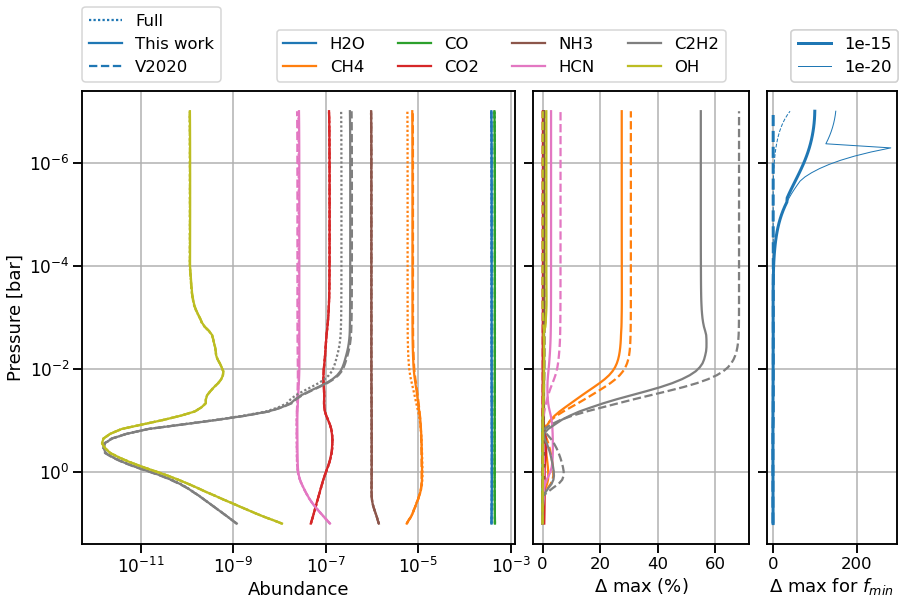

In [112]:
def bolognese(test_df, to_beat_df, to_match_df, imp_molecs=imp_molecs, figsize=(13,9),
             legend_coords0=(0., 1.02), legend_coords1=(0.45, 1.02), legend_coords2=(1.64, 1.02),
             fname='pasta', fontsize=17, tick_size=17, 
             cmap='cubehelix', gridspec_kw={'wspace': .07, 'hspace': .2, 'width_ratios':[1, .5, .3] },
             ignore_cols = ['height[km]', 'pressure[bar]','temperature[K]', 'MMW[g]', 'nan'],
             abunmins=[1e-15, 1e-20], linewidth=3):
    plt.close('all')
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=figsize, gridspec_kw=gridspec_kw,
                             sharey=True)
    get_cmap = cm.get_cmap(cmap)
    ax_abs = axes[0]
    ax_rel = axes[1]
    ax_dev = axes[2]

    for m, m_i in zip(imp_molecs, range(len(imp_molecs))):
        m_color = get_cmap(m_i/len(imp_molecs))
        p = to_match_df['pressure[bar]']
        ax_abs.plot(10**to_match_df[m], p,  linestyle=(0, (1, 1)), color= m_color)
        ax_abs.plot(10**test_df[m], test_df['pressure[bar]'], color = m_color)

        ax_abs.plot(10**to_beat_df[m], to_beat_df['pressure[bar]'],  color = m_color,
                      linestyle='--')
        to_match = 10**to_match_df[m]

        ax_rel.plot((np.abs(10**test_df[m] - to_match)/to_match)*100, p, color=m_color)
        ax_rel.plot((np.abs(10**to_beat_df[m] - to_match)/to_match)*100, p, color=m_color,
                    linestyle='--')
        
    to_play = to_match_df.copy()
    to_play_test = test_df.copy()
    to_play_beat = to_beat_df.copy()
    pressure = to_match_df['pressure[bar]']

    to_play = to_play.drop(ignore_cols, axis=1)
    to_play_test = to_play_test.drop(ignore_cols, axis=1)
    to_play_beat = to_play_beat.drop(ignore_cols, axis=1)
    for abunmin in abunmins:
        log_abumnin = np.log10(abunmin)
        for df, linest in zip([to_play_test, to_play_beat], ['solid', '--']):
            to_play_df = to_play.filter(items=df.columns)
            mask_abun = to_play_df>log_abumnin
            to_play_df = to_play_df[mask_abun]
            df = df[mask_abun]
            to_play_df = np.abs(10**df - 10**to_play_df)/10**to_play_df
            max_dev = to_play_df.max(axis=1)
            mask_nan = [not np.isnan(aux)for aux in max_dev]
            ax_dev.plot(max_dev[mask_nan], pressure[mask_nan], linestyle=linest, color=get_cmap(0),
                        linewidth=linewidth)
        linewidth-=2
  
        
    lines = ax_abs.get_lines()
    legend0 = ax_abs.legend([lines[i] for i in [0,1,2]], ["Full", "This work", "V2020"], loc=legend_coords0)
    legend1 = ax_abs.legend([lines[3*m_i+1] for m_i in range(len(imp_molecs))], imp_molecs, loc=legend_coords1,
                         ncol=int(len(imp_molecs)/2))
    lines = ax_dev.get_lines()
    legend2 = ax_abs.legend([lines[2*j] for j in range(len(abunmins))], abunmins, loc=legend_coords2)
    ax_abs.set_ylabel('Pressure [bar]')
    ax_abs.set_xlabel('Abundance')
    ax_rel.set_xlabel(r'$\Delta$ max $(\%)$')
    ax_dev.set_xlabel(r'$\Delta$ max for $f_{min}$' )
    ax_abs.add_artist(legend0)
    ax_abs.add_artist(legend1)
    ax_abs.add_artist(legend2)
    ax_abs.tick_params(axis='both', which='major', labelsize=tick_size)
    for ax in axes:
        ax.xaxis.grid(True, 'major')
        ax.yaxis.grid(True, 'major')
    ax_abs.set_yscale('log')
    ax_abs.invert_yaxis()
        

    ax_abs.set_xscale('log')
    #ax_rel.set_xscale('log')
    #ax_dev.set_xscale('log')
    plt.yticks(fontsize=fontsize)
    plt.subplots_adjust(bottom=0.15, top=0.85, left=0.1, right=0.97)
    fig.savefig(fname+'.pdf')
bolognese(dfs_to_test[0][1], dfs_to_test[1][1], dfs_to_test[0][0], cmap='tab10')
    


In [ ]:
imp_molecs

In [ ]:
imp_molecs = [ 'CH4', 'H2O', 'CO', 'CO2', 'C2H2', 'NH3', 'HCN', 'OH']
spagetti(dfs_to_test[0][1], dfs_to_test[1][1], dfs_to_test[0][0], imp_molecs=imp_molecs, figsize=(15,18), 
        coral_model='this work', legend_coords=(0.9, 1.5), fontsize=20, 
        gridspec_kw={'wspace': .22,'hspace': .4, 'width_ratios':[1,.3, 1, .3] })


In [ ]:
def err_analysis(dfs, errs, rtol=1e-5, abunminsteady=1e-20,figsize=(10,6), plot_unmasked=True):
    min_e = np.argmin(errs)
    df = dfs[min_e]
    print(min_e, len(errs))
    o_df=dfs[min_e-1]
    cols = df.columns[3:-1]
    all_y = 10**df[cols].values
    o_all_y =10**o_df[cols].values

    heights=len(all_y)
    species=len(all_y[0])

    errsteady = np.zeros((heights,species))
    mask_abun = np.ones((heights, species), dtype=bool)

    for z in range(heights):
        for i in range(len(all_y[0])):
            errsteady[z,i]= np.abs(all_y[z,i] - o_all_y[z,i])/o_all_y[z,i] 
            mask_abun[z,i]= all_y[z,i]>=abunminsteady

    plt.close('all')
    fig = plt.figure(figsize=figsize)
    grid = gridspec.GridSpec(2, 2, wspace=0.4, hspace=0.3)
    x=df['height[km]'].values
    err_per_z = np.array([np.nanmean(errsteady[z]) for z in range(heights)])
    masked_err_per_z= np.array([np.nanmean(errsteady[z][mask_abun[z]]) for z in range(heights)])
    ax = fig.add_subplot(grid[:, 0])
    ax.plot(x, masked_err_per_z, '.')
    if plot_unmasked: ax.plot(x, err_per_z,'.',alpha=0.9, color='coral')
    ax.set_xlabel('height')
    ax.set_ylabel('mean errsteady')
    ax0 = fig.add_subplot(grid[0, 1])
    errsteady1d=errsteady.flatten()
    errsteady1d_masked = errsteady[mask_abun].flatten()
    ax0.hist(errsteady1d, color='coral')
    ax0.set_title('errsteady')
    ax1 = fig.add_subplot(grid[1, 1])
    ax1.hist(errsteady1d_masked)
    ax1.set_title('errsteady for y>abunmin')
    print(np.nanmax(errsteady1d_masked))
    return errsteady1d, errsteady1d_masked
    
#est0, est_masked0 =err_analysis(dfs0, errs0)

In [ ]:
def get_hdf(df_i, df_ii, m='H2O'):
    molecs = df_i.columns[3:-1]
    
    if m == '':
        hdf = pd.DataFrame(index=df_i.index, columns=molecs)
        for m in molecs:
            ref_values = df_i[m]
            new_values = df_ii[m]
            hdf[m] = np.abs(10**(new_values-ref_values)-1)
    else:
        hdf = hdf = pd.DataFrame(index=df_i.index, columns=[m])
        ref_values = df_i[m]
        new_values = df_ii[m]
        hdf[m] = np.abs(10**(new_values-ref_values)-1)
        print (np.where(df_i.columns==m))
        
    return hdf

def get_hdfs(dfs_, m='H2O'):
    return [get_hdf(dfs_[i], dfs_[i+1], m=m) for i in range(len(dfs_)-1)]
hdfs = get_hdfs(dfs0, m='')   


In [ ]:
def height_analysis(hdf, mask_by_rtol=True, rtol=1e-5, color_pos='forestgreen',
                   color_neg='gray', alpha=0.9, flag='',figsize=(15,5)):
    
    plt.close('all')
    fig = plt.figure(figsize=figsize)
    grid = gridspec.GridSpec(2,1, hspace=.3, height_ratios=[2, 1.])
    ax_heights = fig.add_subplot(grid[0])
    ax_hist = fig.add_subplot(grid[1])
    for h in hdf.index:
        data = hdf.iloc[h]
        if mask_by_rtol:
            data = data[data>=rtol]
        if len(data)>0:
            x = np.mean(data)
            ax_heights.errorbar(h, x , yerr=np.array([[np.abs(x - np.min(data)), x + np.max(data)]]).T, 
                            color=color_pos, marker = '.', capsize=1.5, alpha=alpha)
            ax_hist.bar(h, len(data), color = color_pos)
        ax_heights.set_yscale('log')
        ax_heights.set_ylabel(r'$ \Delta X / X $')
        if flag != '':
            ax_heights.set_title(flag)
"""
for i in range(0,len(hdfs)-1):
    height_analysis(hdfs[i], flag=i)
    plt.show()
"""


In [ ]:
def change_per_height(dfs, times, errs, h=99, molecs=[],figsize=(15,2), errsteady=1e-4, abunmin=1e-20):
    if len(molecs) == 0:
        molecs = dfs[0].columns[3:-1]
    mdf = pd.DataFrame(index=range(len(dfs)), columns=molecs)
    #grid = gridspec.GridSpec(2,1, hspace=.1)
    plt.close('all')
    fig = plt.figure(figsize=figsize)
    ax_molec = fig.add_subplot(111)
    for m, ind_m in zip(molecs, range(len(molecs))):
        for ind in range(len(dfs)):
            if ind == 0:
                mdf.at[ind, m] = 10**dfs[ind][m][h]
            else:
                prev = 10**dfs[ind-1][m][h]
                mdf.at[ind,m] = np.abs(10**dfs[ind][m][h] - prev)/prev
    for t in range(1, len(times)):
        abunbig = []
        abunsmall = []
        for m in molecs:
            if mdf.at[0,m] > abunmin:
                abunbig.append(mdf.iloc[t][m])
            else:
                abunsmall.append(mdf.iloc[t][m])
        widths = 0.5    
        ax_molec.plot(t, np.max(abunbig), color='blue', marker='+')
        ax_molec.plot(t+0.3, np.max(abunsmall), color='coral', marker='+')
        
    ax_molec.set_yscale('log') 
    #ax_molec.set_xscale('log')
    ax_molec.set_xlabel('times')
    ax_molec.set_ylabel(r'$ max(\Delta X / X )$')
    ax_molec.set_title('Height = '+str(h))
    ax_molec.axhline(y=errsteady, linestyle='--', color='gray')
    plt.subplots_adjust(bottom=0.18, top=0.8, left=0.15, right=0.95)
    fig.savefig(str(h)+'.png')
    return mdf

for h in [0,30,50,80,99]:
    change_per_height(dfs, times, errs, h=h)
    plt.show()

In [ ]:
def change_per_height(dfs, times, errs, molecs=[],figsize=(15,2), errsteady=1e-4, abunmin=1e-20):
    if len(molecs) == 0:
        molecs = dfs[0].columns[3:-1]
    mdf = pd.DataFrame(index=range(len(dfs)), columns=molecs)
    plt.close('all')
    fig = plt.figure(figsize=figsize)
    ax_molec = fig.add_subplot(111)
    for m, ind_m in zip(molecs, range(len(molecs))):
        for ind in range(len(dfs)):
            if ind == 0:
                mdf.at[ind, m] = 10**dfs[ind][m][h]
            else:
                prev = 10**dfs[ind-1][m][h]
                mdf.at[ind,m] = np.abs(10**dfs[ind][m][h] - prev)/prev
    for t in range(len(times[1:])):
        abunbig = []
        abunsmall = []
        for m in molecs:
            if mdf.at[0,m] > abunmin:
                abunbig.append(mdf.iloc[t][m])
            else:
                abunsmall.append(mdf.iloc[t][m])
        widths = 0.5    
        ax_molec.plot(t, np.max(abunbig), color='blue', marker='+')
        ax_molec.plot(t+0.3, np.max(abunsmall), color='coral', marker='+')
        
    ax_molec.set_yscale('log') 
    #ax_molec.set_xscale('log')
    ax_molec.set_xlabel('times')
    ax_molec.set_ylabel(r'$ max(\Delta X / X )$')
    ax_molec.set_title('Height = '+str(h))
    ax_molec.axhline(y=errsteady, linestyle='--', color='gray')
    return mdf